In [1]:
import pandas as pd
##database loading
df = pd.read_csv("Autism_Data.csv")

##eda explantory data analysis
print(df.shape)
print(df.head())
print(df.info())

(704, 21)
   A1_Score  A2_Score  A3_Score  A4_Score  A5_Score  A6_Score  A7_Score  \
0         1         1         1         1         0         0         1   
1         1         1         0         1         0         0         0   
2         1         1         0         1         1         0         1   
3         1         1         0         1         0         0         1   
4         1         0         0         0         0         0         0   

   A8_Score  A9_Score  A10_Score  ... gender       ethnicity jundice austim  \
0         1         0          0  ...      f  White-European      no     no   
1         1         0          1  ...      m          Latino      no    yes   
2         1         1          1  ...      m          Latino     yes    yes   
3         1         0          1  ...      f  White-European      no    yes   
4         1         0          0  ...      f               ?      no     no   

     contry_of_res used_app_before result       age_desc relatio

In [2]:
#data preprocessing

print(df.isnull().sum())

print((df == '?').sum())

print(df.duplicated().sum())

A1_Score           0
A2_Score           0
A3_Score           0
A4_Score           0
A5_Score           0
A6_Score           0
A7_Score           0
A8_Score           0
A9_Score           0
A10_Score          0
age                0
gender             0
ethnicity          0
jundice            0
austim             0
contry_of_res      0
used_app_before    0
result             0
age_desc           0
relation           0
Class/ASD          0
dtype: int64
A1_Score            0
A2_Score            0
A3_Score            0
A4_Score            0
A5_Score            0
A6_Score            0
A7_Score            0
A8_Score            0
A9_Score            0
A10_Score           0
age                 2
gender              0
ethnicity          95
jundice             0
austim              0
contry_of_res       0
used_app_before     0
result              0
age_desc            0
relation           95
Class/ASD           0
dtype: int64
5


In [3]:
pd.set_option('display.max_rows', None)
print((df == '?').sum())

A1_Score            0
A2_Score            0
A3_Score            0
A4_Score            0
A5_Score            0
A6_Score            0
A7_Score            0
A8_Score            0
A9_Score            0
A10_Score           0
age                 2
gender              0
ethnicity          95
jundice             0
austim              0
contry_of_res       0
used_app_before     0
result              0
age_desc            0
relation           95
Class/ASD           0
dtype: int64


In [ ]:
print("Before:", df.shape)
df = df.drop_duplicates()
print("After:", df.shape)

Before: (704, 21)
After: (699, 21)


In [5]:
df = df.drop(columns=['age_desc', 'used_app_before', 'result']) ##removing unnecessary col
print(df.shape)
print(df.columns.tolist())

(699, 18)
['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender', 'ethnicity', 'jundice', 'austim', 'contry_of_res', 'relation', 'Class/ASD']


In [6]:
df['age'] = pd.to_numeric(df['age'], errors='coerce') ##pd.to_numeric(..., errors='coerce') tries to convert the age column to actual numbers
##. Any value it can't convert — like '?' — becomes NaN (missing) instead of crashing.
print(df['age'].isnull().sum())
print(df['age'].max())

2
383.0


In [7]:
df.loc[df['age'] > 100, 'age'] = None
print(df['age'].isnull().sum())

3


In [8]:
median_age = df['age'].median()
df['age'] = df['age'].fillna(median_age)
print(median_age)
print(df['age'].isnull().sum())

27.0
0


In [9]:
df['ethnicity'] = df['ethnicity'].replace('?', 'Unknown')
df['relation'] = df['relation'].replace('?', 'Unknown')
print(df['ethnicity'].value_counts())
print(df['relation'].value_counts())

ethnicity
White-European       230
Asian                123
Unknown               95
'Middle Eastern '     90
Black                 43
'South Asian'         36
Others                30
Latino                20
Hispanic              13
Pasifika              12
Turkish                6
others                 1
Name: count, dtype: int64
relation
Self                          519
Unknown                        95
Parent                         50
Relative                       26
Others                          5
'Health care professional'      4
Name: count, dtype: int64


In [10]:
top_countries = df['contry_of_res'].value_counts().nlargest(10).index ##Finds the 10 most common countries in your data.Anything outside that top 10 gets relabeled as "Other".
df['contry_of_res'] = df['contry_of_res'].apply(lambda x: x if x in top_countries else 'Other')
print(df['contry_of_res'].value_counts())

contry_of_res
Other                     154
'United States'           111
'New Zealand'              81
India                      81
'United Arab Emirates'     80
'United Kingdom'           76
Jordan                     47
Australia                  27
Canada                     15
'Sri Lanka'                14
Afghanistan                13
Name: count, dtype: int64


In [11]:
from sklearn.preprocessing import LabelEncoder ##to convert f to 1 and m to 0

le = LabelEncoder()
df['gender'] = le.fit_transform(df['gender'])
df['jundice'] = le.fit_transform(df['jundice'])
df['austim'] = le.fit_transform(df['austim'])
df['Class/ASD'] = le.fit_transform(df['Class/ASD'])

print(df[['gender', 'jundice', 'austim', 'Class/ASD']].head())

   gender  jundice  austim  Class/ASD
0       0        0       0          0
1       1        0       1          0
2       1        1       1          1
3       0        0       1          0
4       0        0       0          0


In [12]:
df['ethnicity'] = df['ethnicity'].str.replace("'", "", regex=False).str.strip()
df['ethnicity'] = df['ethnicity'].replace({'others': 'Others'})
df['contry_of_res'] = df['contry_of_res'].str.replace("'", "", regex=False).str.strip()

print(df['ethnicity'].unique())
print(df['contry_of_res'].unique())

['White-European' 'Latino' 'Unknown' 'Others' 'Black' 'Asian'
 'Middle Eastern' 'Pasifika' 'South Asian' 'Hispanic' 'Turkish']
['United States' 'Other' 'New Zealand' 'Jordan' 'United Arab Emirates'
 'Afghanistan' 'United Kingdom' 'Australia' 'Canada' 'India' 'Sri Lanka']


In [13]:
df = pd.get_dummies(df, columns=['ethnicity', 'relation', 'contry_of_res'], drop_first=True)
print(df.shape)
print(df.columns.tolist())


(699, 40)
['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender', 'jundice', 'austim', 'Class/ASD', 'ethnicity_Black', 'ethnicity_Hispanic', 'ethnicity_Latino', 'ethnicity_Middle Eastern', 'ethnicity_Others', 'ethnicity_Pasifika', 'ethnicity_South Asian', 'ethnicity_Turkish', 'ethnicity_Unknown', 'ethnicity_White-European', 'relation_Others', 'relation_Parent', 'relation_Relative', 'relation_Self', 'relation_Unknown', 'contry_of_res_Australia', 'contry_of_res_Canada', 'contry_of_res_India', 'contry_of_res_Jordan', 'contry_of_res_New Zealand', 'contry_of_res_Other', 'contry_of_res_Sri Lanka', 'contry_of_res_United Arab Emirates', 'contry_of_res_United Kingdom', 'contry_of_res_United States']


Preprocessing is done!
Removed duplicates and useless/leaky columns
Fixed the age outlier and missing values
Handled missing categorical data as "Unknown"
Grouped high-cardinality contry_of_res
Cleaned text formatting issues
Encoded binary columns with LabelEncoder
One-hot encoded multi-category columns

In [14]:
##feature extraction
X = df.drop('Class/ASD', axis=1)
y = df['Class/ASD']

print(X.shape)
print(y.shape)

(699, 39)
(699,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(559, 39) (140, 39)
Class/ASD
0    409
1    150
Name: count, dtype: int64
Class/ASD
0    103
1     37
Name: count, dtype: int64


In [16]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(y_pred[:10])

[1 0 0 0 0 1 0 0 0 0]


In [17]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

print(classification_report(y_test, y_pred))

Accuracy: 0.9714285714285714
Confusion Matrix:
[[103   0]
 [  4  33]]
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       103
           1       1.00      0.89      0.94        37

    accuracy                           0.97       140
   macro avg       0.98      0.95      0.96       140
weighted avg       0.97      0.97      0.97       140



In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9428571428571428
Confusion Matrix:
[[101   2]
 [  6  31]]
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       103
           1       0.94      0.84      0.89        37

    accuracy                           0.94       140
   macro avg       0.94      0.91      0.92       140
weighted avg       0.94      0.94      0.94       140



In [19]:
from sklearn.svm import SVC

svm_model = SVC(random_state=42)
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.7357142857142858
Confusion Matrix:
[[103   0]
 [ 37   0]]
              precision    recall  f1-score   support

           0       0.74      1.00      0.85       103
           1       0.00      0.00      0.00        37

    accuracy                           0.74       140
   macro avg       0.37      0.50      0.42       140
weighted avg       0.54      0.74      0.62       140



c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [20]:
##feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

SVM Accuracy: 0.9214285714285714
Confusion Matrix:
[[100   3]
 [  8  29]]
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       103
           1       0.91      0.78      0.84        37

    accuracy                           0.92       140
   macro avg       0.92      0.88      0.89       140
weighted avg       0.92      0.92      0.92       140



Metric            Logistic Regression   	Random Forest	  SVM (scaled)
Accuracy            	97.14%	              94.29%	         92.14%
False Positives	        0	                     2	             3
False Negatives       	4	                     6	             8
Precision (ASD class)	1.00	                 0.94	         0.91
Recall (ASD class)   	0.89	                 0.84	         0.78
F1-score (ASD class)	0.94	                 0.89	         0.84

Logistic Regression is the best-performing model across every metric for this datase





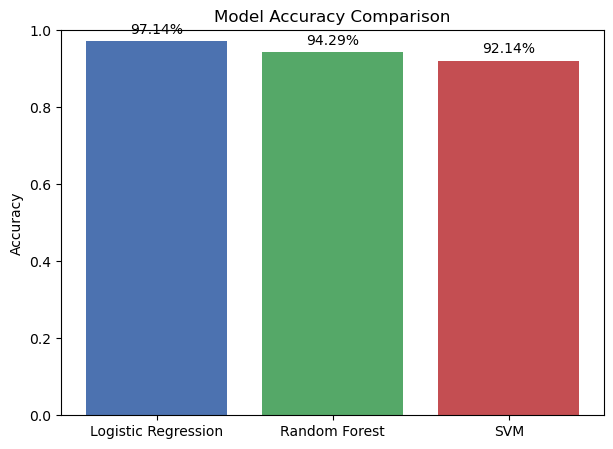

In [22]:
import matplotlib.pyplot as plt

models = ['Logistic Regression', 'Random Forest', 'SVM']
accuracies = [
    accuracy_score(y_test, y_pred),
    accuracy_score(y_test, y_pred_rf),
    accuracy_score(y_test, y_pred_svm)
]

plt.figure(figsize=(7,5))
bars = plt.bar(models, accuracies, color=['#4C72B0', '#55A868', '#C44E52'])
plt.ylim(0, 1)
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, acc + 0.02, f'{acc:.2%}', ha='center')

plt.show()

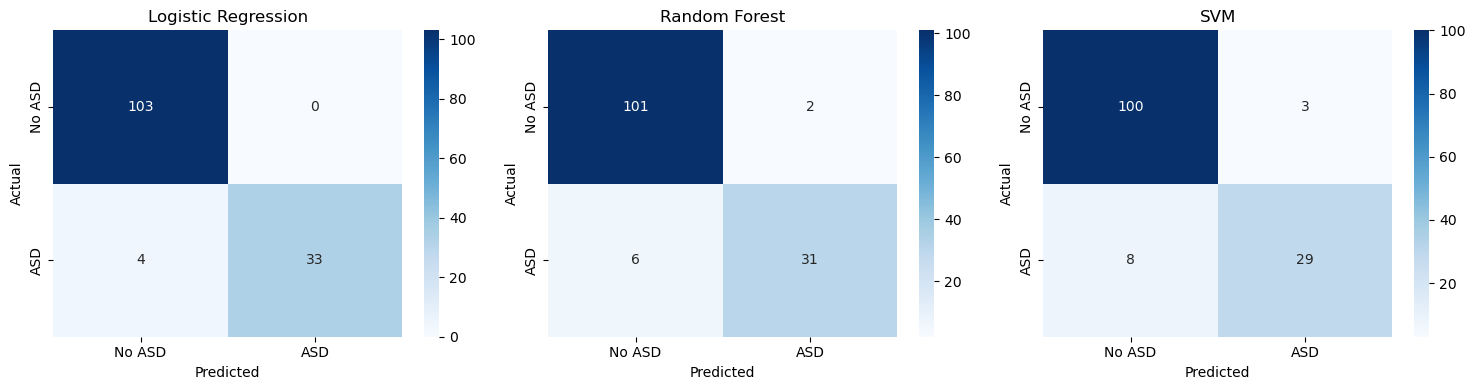

In [23]:
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15,4))

cms = [
    confusion_matrix(y_test, y_pred),
    confusion_matrix(y_test, y_pred_rf),
    confusion_matrix(y_test, y_pred_svm)
]
titles = ['Logistic Regression', 'Random Forest', 'SVM']

for ax, cm, title in zip(axes, cms, titles):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No ASD', 'ASD'], yticklabels=['No ASD', 'ASD'])
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", grid_search.best_score_)

Best parameters: {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Best cross-validation accuracy: 0.9964124839124839


In [25]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print("Tuned Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))
print(classification_report(y_test, y_pred_tuned))

Tuned Logistic Regression Accuracy: 1.0
Confusion Matrix:
[[103   0]
 [  0  37]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       103
           1       1.00      1.00      1.00        37

    accuracy                           1.00       140
   macro avg       1.00      1.00      1.00       140
weighted avg       1.00      1.00      1.00       140



In [26]:
from sklearn.metrics import roc_curve, auc

# Get prediction probabilities/scores for each model
y_prob_lr = model.predict_proba(X_test)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_score_svm = svm_model.decision_function(X_test_scaled)

# Compute ROC curve points
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_score_svm)

# Compute AUC for each
auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)
auc_svm = auc(fpr_svm, tpr_svm)

print("AUC - Logistic Regression:", auc_lr)
print("AUC - Random Forest:", auc_rf)
print("AUC - SVM:", auc_svm)

AUC - Logistic Regression: 0.9965888218315403
AUC - Random Forest: 0.9880608764103909
AUC - SVM: 0.9845184990816059


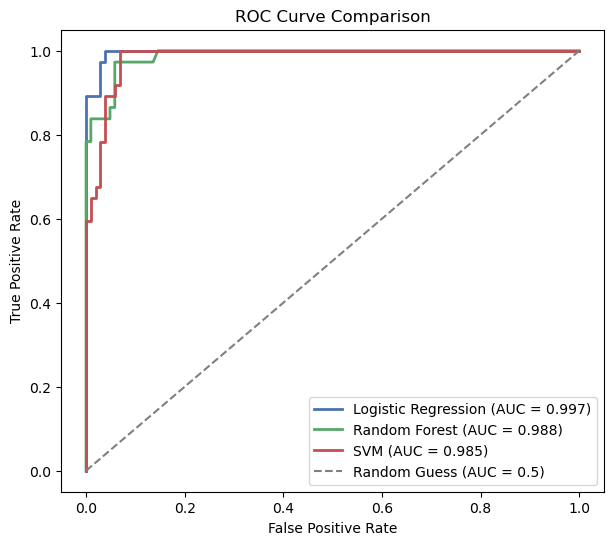

In [27]:
plt.figure(figsize=(7,6))

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.3f})', color='#4C72B0', linewidth=2)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', color='#55A868', linewidth=2)
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc_svm:.3f})', color='#C44E52', linewidth=2)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess (AUC = 0.5)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.show()

In [28]:
print(X_train.columns.tolist())

['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'gender', 'jundice', 'austim', 'ethnicity_Black', 'ethnicity_Hispanic', 'ethnicity_Latino', 'ethnicity_Middle Eastern', 'ethnicity_Others', 'ethnicity_Pasifika', 'ethnicity_South Asian', 'ethnicity_Turkish', 'ethnicity_Unknown', 'ethnicity_White-European', 'relation_Others', 'relation_Parent', 'relation_Relative', 'relation_Self', 'relation_Unknown', 'contry_of_res_Australia', 'contry_of_res_Canada', 'contry_of_res_India', 'contry_of_res_Jordan', 'contry_of_res_New Zealand', 'contry_of_res_Other', 'contry_of_res_Sri Lanka', 'contry_of_res_United Arab Emirates', 'contry_of_res_United Kingdom', 'contry_of_res_United States']


In [29]:
print(df.shape)
print(X_train.shape[1])

(699, 40)
39


In [30]:
import joblib
enc = joblib.load('label_encoder.pkl')
print(type(enc))

<class 'dict'>


In [31]:
from sklearn.preprocessing import LabelEncoder
import joblib

binary_cols = ['gender', 'jundice', 'austim']

encoders = {}
for col in binary_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

joblib.dump(encoders, 'label_encoder.pkl')  # overwrite with the correct dict version

['label_encoder.pkl']

In [32]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Split FIRST — this is the correct, leak-free order
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SMOTE only on training data
sm = SMOTE(random_state=42)
X_train, y_train = sm.fit_resample(X_train, y_train)

c:\Users\DELL\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\DELL\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\DELL\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\DELL\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression(C=100, penalty='l1', solver='liblinear', max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9285714285714286
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       103
           1       0.86      0.86      0.86        37

    accuracy                           0.93       140
   macro avg       0.91      0.91      0.91       140
weighted avg       0.93      0.93      0.93       140



In [34]:
import joblib

joblib.dump(model, 'asd_model.pkl')
joblib.dump(X_train.columns.tolist(), 'model_columns.pkl')  # important - preserves exact column order

['model_columns.pkl']

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import joblib

model = LogisticRegression(C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

joblib.dump(model, 'asd_model.pkl')
joblib.dump(X_train.columns.tolist(), 'model_columns.pkl')

Accuracy: 0.9571428571428572
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       103
           1       0.92      0.92      0.92        37

    accuracy                           0.96       140
   macro avg       0.94      0.94      0.94       140
weighted avg       0.96      0.96      0.96       140



['model_columns.pkl']

                        Feature  Coefficient  Abs_Coefficient
4                      A5_Score     2.405107         2.405107
8                      A9_Score     2.317855         2.317855
34          contry_of_res_Other     1.808775         1.808775
9                     A10_Score     1.753251         1.753251
15           ethnicity_Hispanic     1.634061         1.634061
5                      A6_Score     1.584083         1.584083
7                      A8_Score     1.579308         1.579308
0                      A1_Score     1.570330         1.570330
6                      A7_Score     1.565858         1.565858
3                      A4_Score     1.544795         1.544795
1                      A2_Score     1.424252         1.424252
30         contry_of_res_Canada     1.375790         1.375790
38  contry_of_res_United States     1.357590         1.357590
2                      A3_Score     1.348121         1.348121
23     ethnicity_White-European     1.339772         1.339772


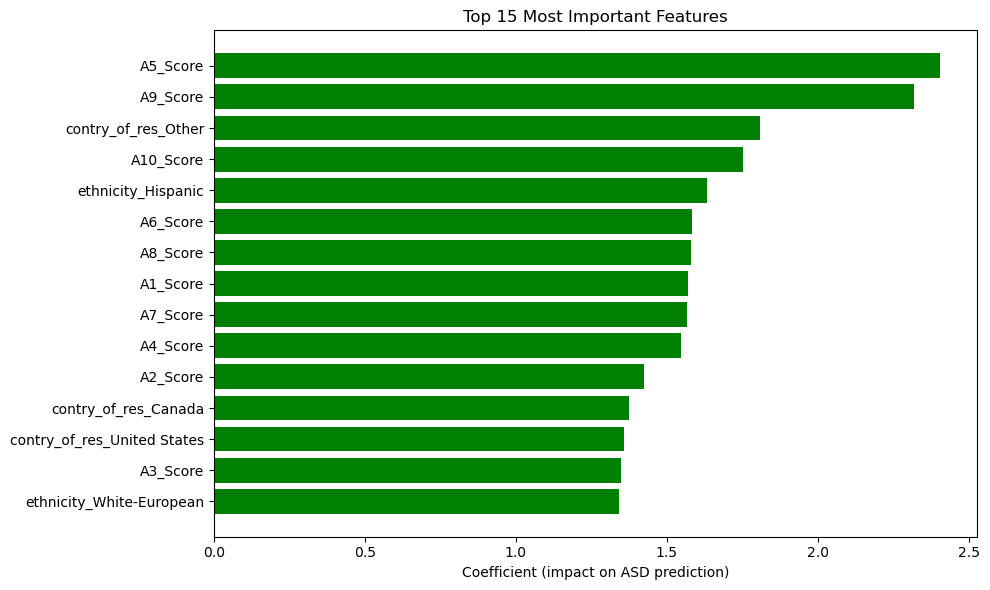

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance directly from Logistic Regression coefficients
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
})

# Sort by absolute impact (both positive and negative matter)
importance_df['Abs_Coefficient'] = importance_df['Coefficient'].abs()
importance_df = importance_df.sort_values('Abs_Coefficient', ascending=False)

print(importance_df.head(15))

# Plot top 15 features
plt.figure(figsize=(10,6))
top15 = importance_df.head(15)
colors = ['red' if c < 0 else 'green' for c in top15['Coefficient']]
plt.barh(top15['Feature'], top15['Coefficient'], color=colors)
plt.xlabel('Coefficient (impact on ASD prediction)')
plt.title('Top 15 Most Important Features')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [40]:
import joblib

joblib.dump(model_reduced, 'asd_model_reduced.pkl')

['asd_model_reduced.pkl']